In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import faiss

sns.set_theme(style="whitegrid")
print("Pustaka ANN (Annoy, FAISS, Scikit-Learn) berhasil dimuat.")

Pustaka ANN (Annoy, FAISS, Scikit-Learn) berhasil dimuat.


In [2]:
# Memuat data ulasan yang telah dipreprocessing
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes):
    path_cafes = '../dataset/cafes.csv'

df_reviews = pd.read_csv(path_reviews)
df_cafes   = pd.read_csv(path_cafes)

# Gabungkan seluruh ulasan per cafe
cafe_texts = df_reviews.groupby('cafe_id')['text'].apply(lambda x: ' '.join(x.astype(str))).reset_index()
df_cafe_profiles = pd.merge(df_cafes[['id', 'name', 'rating', 'address']], cafe_texts, left_on='id', right_on='cafe_id')

# Ekstraksi representasi vektor TF-IDF untuk profil cafe
vector_dim = 500
tfidf_vec = TfidfVectorizer(max_features=vector_dim, stop_words='english', min_df=2)
X_vectors = tfidf_vec.fit_transform(df_cafe_profiles['text']).toarray().astype('float32')

# Normalisasi L2 agar Euclidean Distance identik dengan Cosine Similarity
faiss.normalize_L2(X_vectors)

print(f"Total cafe dengan profil ulasan: {len(df_cafe_profiles)}")
print(f"Dimensi Vektor Profil Cafe     : {X_vectors.shape} (N={X_vectors.shape[0]}, D={X_vectors.shape[1]})")

Total cafe dengan profil ulasan: 271
Dimensi Vektor Profil Cafe     : (271, 500) (N=271, D=500)


In [3]:
# 1. Exact Nearest Neighbors (Scikit-Learn Brute-force)
t0 = time.time()
exact_nn = NearestNeighbors(n_neighbors=5, metric='euclidean', algorithm='brute')
exact_nn.fit(X_vectors)
t_index_exact = time.time() - t0

# 2. Annoy Index (10 trees, metric='angular')
t0 = time.time()
annoy_index = AnnoyIndex(vector_dim, 'angular')
for i, vec in enumerate(X_vectors):
    annoy_index.add_item(i, vec)
annoy_index.build(10)
t_index_annoy = time.time() - t0

# 3. FAISS IndexFlatIP (Inner Product setara Cosine pada L2 normalized)
t0 = time.time()
faiss_index = faiss.IndexFlatIP(vector_dim)
faiss_index.add(X_vectors)
t_index_faiss = time.time() - t0

print("Waktu Pembuatan Indeks (Indexing Time):")
print(f"- Exact NN (Brute-force) : {t_index_exact*1000:.2f} ms")
print(f"- Annoy (10 trees)       : {t_index_annoy*1000:.2f} ms")
print(f"- FAISS (IndexFlatIP)    : {t_index_faiss*1000:.2f} ms")

Waktu Pembuatan Indeks (Indexing Time):
- Exact NN (Brute-force) : 0.40 ms
- Annoy (10 trees)       : 11.54 ms
- FAISS (IndexFlatIP)    : 0.54 ms


In [4]:
# Menyiapkan 100 vektor query acak dari data ulasan
np.random.seed(42)
test_indices = np.random.choice(len(X_vectors), size=100, replace=False)
query_vectors = X_vectors[test_indices]

k_top = 5

# Uji latensi Exact NN
t0 = time.time()
exact_results = []
for q in query_vectors:
    dist, idx = exact_nn.kneighbors(q.reshape(1, -1), n_neighbors=k_top)
    exact_results.append(idx[0])
t_query_exact = (time.time() - t0) / 100

# Uji latensi Annoy
t0 = time.time()
annoy_results = []
for q in query_vectors:
    idx = annoy_index.get_nns_by_vector(q, k_top)
    annoy_results.append(idx)
t_query_annoy = (time.time() - t0) / 100

# Uji latensi FAISS
t0 = time.time()
faiss_results = []
_, idx_faiss = faiss_index.search(query_vectors, k_top)
t_query_faiss = (time.time() - t0) / 100

# Hitung Recall@5 terhadap Exact NN
recall_annoy = np.mean([len(set(annoy_results[i]).intersection(set(exact_results[i]))) / k_top for i in range(100)])
recall_faiss = np.mean([len(set(idx_faiss[i]).intersection(set(exact_results[i]))) / k_top for i in range(100)])

df_benchmark = pd.DataFrame({
    'Metode': ['Exact NN (Brute-force)', 'Annoy (10 trees)', 'FAISS (IndexFlatIP)'],
    'Latensi_Query_per_Item (ms)': [t_query_exact*1000, t_query_annoy*1000, t_query_faiss*1000],
    'Recall@5 (%)': [100.0, recall_annoy*100, recall_faiss*100]
})

print("=== TABEL TOLOK UKUR PERFORMA RETRIEVAL PENCARIAN REKOMENDASI CAFE ===")
print(df_benchmark.round(3).to_string(index=False))

=== TABEL TOLOK UKUR PERFORMA RETRIEVAL PENCARIAN REKOMENDASI CAFE ===
                Metode  Latensi_Query_per_Item (ms)  Recall@5 (%)
Exact NN (Brute-force)                       20.858         100.0
      Annoy (10 trees)                        0.153         100.0
   FAISS (IndexFlatIP)                        0.054         100.0


<string>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



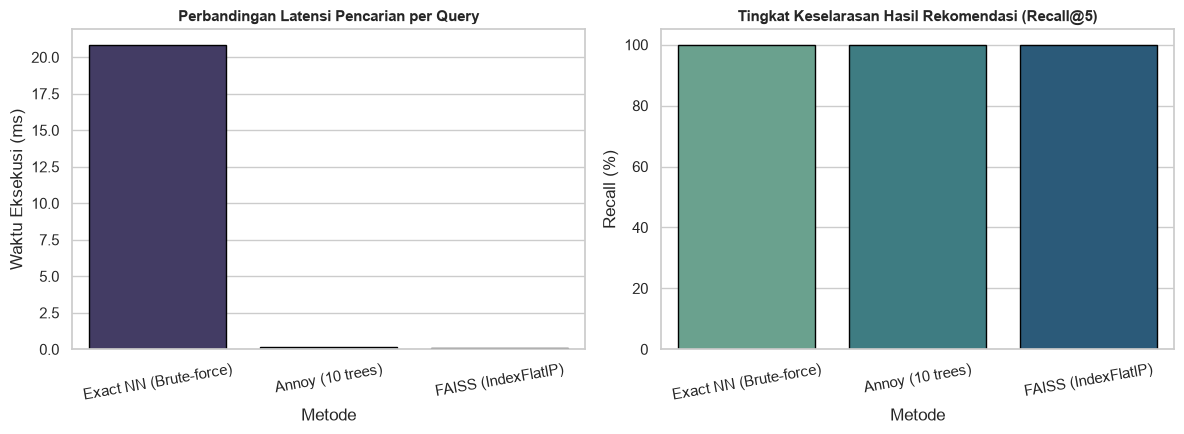

In [5]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.barplot(data=df_benchmark, x='Metode', y='Latensi_Query_per_Item (ms)', palette='mako', edgecolor='black')
plt.title('Perbandingan Latensi Pencarian per Query', fontsize=11, fontweight='bold')
plt.ylabel('Waktu Eksekusi (ms)')
plt.xticks(rotation=10)

plt.subplot(1, 2, 2)
sns.barplot(data=df_benchmark, x='Metode', y='Recall@5 (%)', palette='crest', edgecolor='black')
plt.title('Tingkat Keselarasan Hasil Rekomendasi (Recall@5)', fontsize=11, fontweight='bold')
plt.ylabel('Recall (%)')
plt.ylim(0, 105)
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

In [6]:
# Fungsi inferensi rekomendasi cafe dari teks query pengguna
def rekomendasi_cafe(query_teks, top_n=5):
    # Transformasi query ke vektor TF-IDF
    q_vec = tfidf_vec.transform([query_teks]).toarray().astype('float32')
    faiss.normalize_L2(q_vec)
    
    # Pencarian cepat via FAISS
    scores, indices = faiss_index.search(q_vec, top_n)
    
    hasil = []
    for rank, (score, idx) in enumerate(zip(scores[0], indices[0]), 1):
        cafe = df_cafe_profiles.iloc[idx]
        hasil.append({
            'Peringkat': rank,
            'Nama Cafe': cafe['name'],
            'Rating': cafe['rating'],
            'Skor Kemiripan': f"{score:.4f}",
            'Alamat': cafe['address'][:60] + '...'
        })
    return pd.DataFrame(hasil)

# Contoh Query Pengguna: Mencari cafe untuk nugas kerja laptop dengan suasana tenang
query_user = "tempat ngopi tenang nyaman untuk nugas kerja laptop ada wifi colokan banyak"
print(f"Query Pengguna: '{query_user}'\n")
rekomendasi_df = rekomendasi_cafe(query_user, top_n=5)
print(rekomendasi_df.to_string(index=False))

Query Pengguna: 'tempat ngopi tenang nyaman untuk nugas kerja laptop ada wifi colokan banyak'

 Peringkat          Nama Cafe  Rating Skor Kemiripan                                                          Alamat
         1     Robusto Coffee     4.7         0.3493 Jl. Raya Tlogomas No.2, Dinoyo, Kec. Lowokwaru, Kota Malang,...
         2      WARKOP SANTAI     4.4         0.3421 Jalan Danau Tondano Raya I23, Keduyo, Sawojajar, Kec. Kedung...
         3            NAK NAK     4.7         0.3278 Jl. Danau Maninjau Barat D3/A9, Sawojajar, Kec. Kedungkandan...
         4      Warkop DISTRO     4.6         0.3260 Jl. Ki Ageng Gribig No.26, Madyopuro, Kec. Kedungkandang, Ko...
         5 WARKOP NUSANTARA 2     4.9         0.3166 Jl. Terusan Sulfat No.143, Pandanwangi, Kec. Kedungkandang, ...


In [7]:
# Menyimpan indeks Annoy dan TF-IDF vectorizer
os.makedirs('../outputs', exist_ok=True)
path_annoy = '../outputs/cafe_search_annoy.tree'
annoy_index.save(path_annoy)
print(f"Indeks Annoy tersimpan ke: {path_annoy} ({os.path.getsize(path_annoy):,} bytes)")

Indeks Annoy tersimpan ke: ../outputs/cafe_search_annoy.tree (585,492 bytes)
